# CP2 — Beyond Joel: Advisor-Score Regressor Experiments

Executes `plan.md`. The earlier notebook (`improve_regressor.ipynb`) is the frozen pre-Joel record;
everything new happens here. Context lives in `fatak_notes.md` (Joel's results, tried-and-rejected
list, numbers to beat).

Structure (mirrors `plan.md`):
- **Phase 0** — foundation: Joel's 75 engineered features (`joel_features.py`), LightGBM with his
  settings, k-fold out-of-fold evaluation, and the **baseline every experiment must beat**
- **Phase A** — feature experiments: A1 dispersion/beyond-nearest, A2 spectral (DCT), A3 assignment commute
- **Phase B** — model experiments: B1 quantile certification, B2 boundary weighting, B3 stacking, B4 pseudo-labels
- **Phase C** — latent-space assessment (PCA/NMF, small autoencoder) + written verdict

In [1]:
# Bootstrap - runs both on Colab and locally in the ps2 repo.
#
# Colab clones the course repo into /content. Locally we reuse the clone that
# ./setup_data.sh puts in data/cp2-repo (gitignored: ~70 MB of course data that
# is not ours to commit). Either way we chdir into it, because utils_public.py
# resolves "datasets/..." and "assets/..." relative to the working directory.
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
COURSE_REPO = "https://github.com/decode-mit/2155-CP2-2026.git"


def _ps2_root(start):
    """Walk up from `start` to the ps2 repo root (the dir holding environment.yml)."""
    d = os.path.abspath(start)
    while True:
        if os.path.exists(os.path.join(d, "environment.yml")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise RuntimeError(f"could not find the ps2 repo root above {start}")
        d = parent


if IN_COLAB:
    COURSE_ROOT = "/content/2155-CP2-2026"
    SUBMISSION_DIR = "/content/submissions"
    PS2_ROOT = "/content"
else:
    # Re-running this cell is safe: cwd is then the course clone, and walking
    # up from data/cp2-repo still lands on the ps2 root.
    PS2_ROOT = _ps2_root(os.getcwd())
    COURSE_ROOT = os.path.join(PS2_ROOT, "data", "cp2-repo")
    SUBMISSION_DIR = os.path.join(PS2_ROOT, "submissions")

if not os.path.isdir(COURSE_ROOT):
    subprocess.run(["git", "clone", "--depth", "1", COURSE_REPO, COURSE_ROOT], check=True)

os.chdir(COURSE_ROOT)
sys.path.insert(0, COURSE_ROOT)
sys.path.insert(0, PS2_ROOT)  # for joel_features.py at the ps2 repo root
os.makedirs(SUBMISSION_DIR, exist_ok=True)

from utils_public import *

print(f"course data: {COURSE_ROOT}")
print(f"submissions: {SUBMISSION_DIR}")

course data: /Users/fb/repos/2.156-ps2/data/cp2-repo
submissions: /Users/fb/repos/2.156-ps2/submissions


## Load data
500k grids; each advisor labeled 5k of them (1%). `ADVISOR_NAMES` indexes columns of `ratings`.

In [2]:
import numpy as np
import pandas as pd

grids = load_grids()
ratings = np.load("datasets/scores.npy")
ADVISOR_NAMES = ["Wellness", "Tax", "Transportation", "Business"]

print(grids.shape, ratings.shape)
print("labels per advisor:", (~np.isnan(ratings)).sum(axis=0))

(500000, 7, 7) (500000, 4)
labels per advisor: [5000 5000 5000 5000]


# Phase 0 — Foundation

## CV experiment harness

Upgrade over the old notebook's single 75/25 split: **5-fold out-of-fold (OOF) predictions on all
5,000 labels, repeated over 3 shuffle seeds**. Every grid is predicted by a model that never trained
on it, every label is used for evaluation, and the seed-to-seed spread shows how much a "win" could
be luck (Joel's logs: the same model's approvals moved 523→550 between shuffles — single splits
flatter winners).

Primary metric unchanged: **recall@98p** — the share of truly valid grids (score ≥ 0.75) the model
certifies while the certified pool stays ≥ 98% truly valid. 0 = certifies nothing at that trust
level; 1 = perfect ranker. Also recorded: yield@98p, PR-AUC (stabler tiebreaker), OOF R² (sanity).

- `feature_fn` / `model_fn` can be a single callable or a dict `{advisor_name: callable}` —
  per-advisor lineups are first-class (Joel's final models differ per advisor).
- `seeds=(0,)` for quick iteration; the default `(0, 1, 2)` for any number you intend to quote.
- One experiment ≈ 4 advisors × 3 seeds × 5 folds = 60 fits (a few minutes with LightGBM).
- `results_table_cv()` pivots mean recall@98p (±spread available via `results_table_cv("recall_spread")`).

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, r2_score
from sklearn.model_selection import KFold

RESULTS_CV = []  # one row per (experiment, advisor)
VALID_THRESHOLD = 0.75
SHUFFLE_SEEDS = (0, 1, 2)


def certify_at_precision(preds, y_true, target=0.98):
    """Walk down the prediction ranking as far as cumulative precision allows.

    Returns (recall, yield_frac) at the deepest depth where the certified pool is still
    >= target precision. recall: certified truly-valid / all truly-valid (0..1, 1 = perfect
    ranker). yield_frac: certified / all grids (ceiling = the valid fraction, ~0.25).
    """
    order = np.argsort(-preds)
    valid = (y_true[order] >= VALID_THRESHOLD)
    cum_valid = np.cumsum(valid)
    cum_precision = cum_valid / np.arange(1, len(valid) + 1)
    ok = np.where(cum_precision >= target)[0]
    if not ok.size:
        return 0.0, 0.0
    deepest = ok[-1]
    return cum_valid[deepest] / valid.sum(), (deepest + 1) / len(valid)


def oof_predict(X, y, model_fn, n_splits=5, seed=0):
    """Out-of-fold predictions: every row predicted by a model fitted without it."""
    oof = np.empty(len(y), dtype=np.float64)
    for train, test in KFold(n_splits, shuffle=True, random_state=seed).split(X):
        model = model_fn()
        model.fit(X[train], y[train])
        oof[test] = model.predict(X[test])
    return oof


def _per_advisor(fn_or_dict, advisor_name):
    return fn_or_dict[advisor_name] if isinstance(fn_or_dict, dict) else fn_or_dict


def run_experiment_cv(name, feature_fn, model_fn, seeds=SHUFFLE_SEEDS, plot=True):
    """OOF-evaluate one recipe per advisor over several fold shuffles; log mean recall@98p.

    feature_fn and model_fn: a callable, or a dict {advisor_name: callable} for per-advisor lineups.
    The scatter shows the first seed's OOF predictions; the title reports the mean over seeds and
    the min-max spread.
    """
    if plot:
        fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharex=True, sharey=True)
    for advisor in range(4):
        aname = ADVISOR_NAMES[advisor]
        grids_subset, y = select_rated_subset(grids, ratings[:, advisor])
        X = _per_advisor(feature_fn, aname)(grids_subset)
        mfn = _per_advisor(model_fn, aname)

        recalls, yields, oof_first = [], [], None
        for seed in seeds:
            oof = oof_predict(X, y, mfn, seed=seed)
            r, yl = certify_at_precision(oof, y)
            recalls.append(r)
            yields.append(yl)
            if oof_first is None:
                oof_first = oof
        spread = max(recalls) - min(recalls)
        RESULTS_CV.append({
            "experiment": name, "advisor": aname,
            "recall_at_98p": float(np.mean(recalls)), "recall_spread": float(spread),
            "yield_at_98p": float(np.mean(yields)),
            "pr_auc": average_precision_score(y >= VALID_THRESHOLD, oof_first),
            "r2_oof": r2_score(y, oof_first),
        })

        if plot:
            ax = axes[advisor]
            ax.scatter(y, oof_first, s=3, c="#DC267F")
            ax.plot([0, 1], [0, 1], c="k", linewidth=2)
            ax.axvline(VALID_THRESHOLD, c="#444444", linewidth=1, linestyle="--")
            ax.set_title(f"{aname}\nrecall@98p = {np.mean(recalls):.2f} (±{spread/2:.2f})")
            ax.spines[["right", "top"]].set_visible(False)
    if plot:
        fig.suptitle(f"{name}  —  OOF predictions, seed {seeds[0]}")
        axes[0].set_ylabel("Predicted (OOF)")
        for ax in axes:
            ax.set_xlabel("Actual")
        plt.tight_layout()
        plt.show()


def results_table_cv(metric="recall_at_98p"):
    """Experiments x advisors for one metric ('recall_at_98p', 'recall_spread', 'yield_at_98p',
    'pr_auc', 'r2_oof'), with a mean column; best experiment at the bottom."""
    df = pd.DataFrame(RESULTS_CV).drop_duplicates(subset=["experiment", "advisor"], keep="last")
    table = df.pivot(index="experiment", columns="advisor", values=metric)[ADVISOR_NAMES]
    table["mean"] = table.mean(axis=1)
    return table.sort_values("mean")

## Feature encodings

- `engineered` — Joel's 75 rotation-invariant features (`joel_features.py`, ported with attribution):
  counts (5), adjacency incl. diagonals (30), distance-to-nearest (20), clusters (10), edge/centre (10)
- `engineered_plus_onehot` — + the 245 one-hot cells (position); Joel's adopted Wellness inputs
- `onehot_plus_adjacency` — the old notebook's best encoding, kept as a cross-notebook sanity anchor

Phase A adds new encodings here, each as `engineered` + one new group.

In [4]:
import joel_features as jf


def engineered(grids):
    return jf.engineered(grids)  # (n, 75)


def engineered_plus_onehot(grids):
    return np.hstack([jf.engineered(grids), jf.onehot(grids)])  # (n, 320)


def adjacency_counts(grids):
    """Old notebook's 15 side-by-side pair counts (kept only for the sanity anchor)."""
    n = grids.shape[0]
    pairs = np.zeros((n, 5, 5), dtype=int)
    h_a, h_b = grids[:, :, :-1], grids[:, :, 1:]
    v_a, v_b = grids[:, :-1, :], grids[:, 1:, :]
    for a, b in [(h_a, h_b), (v_a, v_b)]:
        lo = np.minimum(a, b).reshape(n, -1)
        hi = np.maximum(a, b).reshape(n, -1)
        np.add.at(pairs, (np.arange(n)[:, None], lo, hi), 1)
    iu = np.triu_indices(5)
    return pairs[:, iu[0], iu[1]]


def onehot_plus_adjacency(grids):
    return np.hstack([jf.onehot(grids), adjacency_counts(grids)])

## The baseline to beat

Joel's final recipe re-measured in *our* harness, so every later experiment is compared under an
identical procedure (no cross-protocol conversion arguments): LightGBM with his exact settings
(600 trees, lr 0.03, 31 leaves, 0.8 row/column subsampling) on the 75 engineered features —
plus the one-hot cells for Wellness, his adopted variant. (His Transportation ensemble and
Business feature groups are *not* reproduced here; this is the strong-and-simple core.)

**Sanity anchor:** his dev-set numbers convert to roughly recall@98p ≈ 0.56 (Wellness, with
one-hot) / 0.81 (Tax) / 0.73 (Transportation) / 0.89 (Business). Our baseline should land in that
neighbourhood — if it's wildly off, the harness is miswired, not the model.

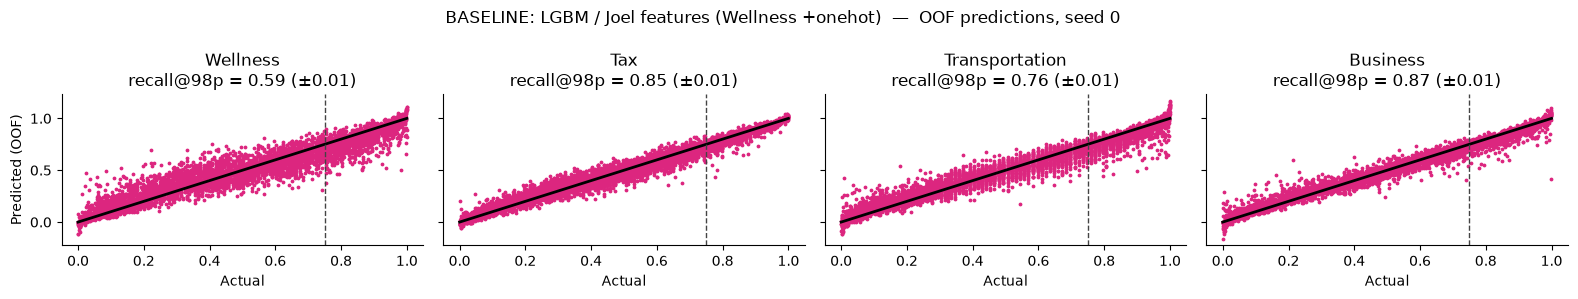

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [5]:
import lightgbm as lgb

# Joel's exact settings (joel_dev validity.py GBM_PARAMS; set by hand, never tuned on data)
GBM_PARAMS = {
    "n_estimators": 600,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "random_state": 0,
    "verbose": -1,
}


def lgbm():
    return lgb.LGBMRegressor(**GBM_PARAMS)


BASELINE_FEATURES = {"Wellness": engineered_plus_onehot, "Tax": engineered,
                     "Transportation": engineered, "Business": engineered}

run_experiment_cv("BASELINE: LGBM / Joel features (Wellness +onehot)", BASELINE_FEATURES, lgbm)
results_table_cv()

## Cross-notebook sanity anchor

Our old best (HistGB on onehot+adjacency) through the new CV harness. Expect recall@98p in the
same ballpark as the old notebook's single-split numbers (~0.17 / 0.59 / 0.09 / 0.43) — likely a
touch higher and steadier, since OOF uses all 5,000 labels. Confirms old and new results live on
one scale; the gap to the baseline above is what Joel's features buy.

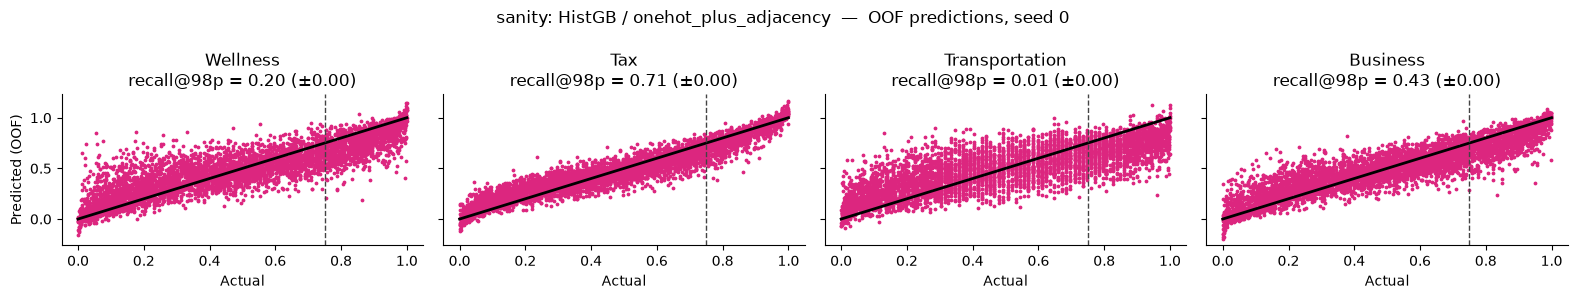

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor

run_experiment_cv("sanity: HistGB / onehot_plus_adjacency", onehot_plus_adjacency,
                  lambda: HistGradientBoostingRegressor(random_state=0), seeds=(0,))
results_table_cv()

# Phase A — Feature experiments

Each experiment adds one new feature group **on top of each advisor's baseline inputs**
(`with_group` below appends to `BASELINE_FEATURES`, so Wellness keeps its one-hot cells). An
experiment earns adoption per advisor only if its recall@98p beats the baseline by more than the
seed spread. None of these groups exists in Joel's 75 features or his 148 lab features
(`fatak_notes.md` has the inventory).

In [7]:
# Phase A setup: append a new feature group to every advisor's baseline inputs.
from joel_features import _COORDS, _STEPS, ABSENT_DISTANCE


def with_group(group_fn):
    """{advisor: baseline features + group_fn's columns} — the Phase A comparison protocol."""
    def extend(base_fn):
        return lambda g: np.hstack([base_fn(g), group_fn(g)])
    return {name: extend(fn) for name, fn in BASELINE_FEATURES.items()}

## A1 — Dispersion & beyond-nearest distances (70 columns)

Joel's distance features only ever ask "how far to the *closest* X?". These describe where each
district *lives* and how it's *spread*:
- per district (20): centroid row/col, RMS spread around the centroid, bounding-box area
- per ordered pair X→Y (25 + 25): mean distance from X cells to **all** Y cells (not just the
  nearest), and mean distance to the **2nd-nearest** Y (one park next door is different from two)

Intuition: "my nearest coffee shop is 2 blocks away" vs. "coffee shops cover the whole city".

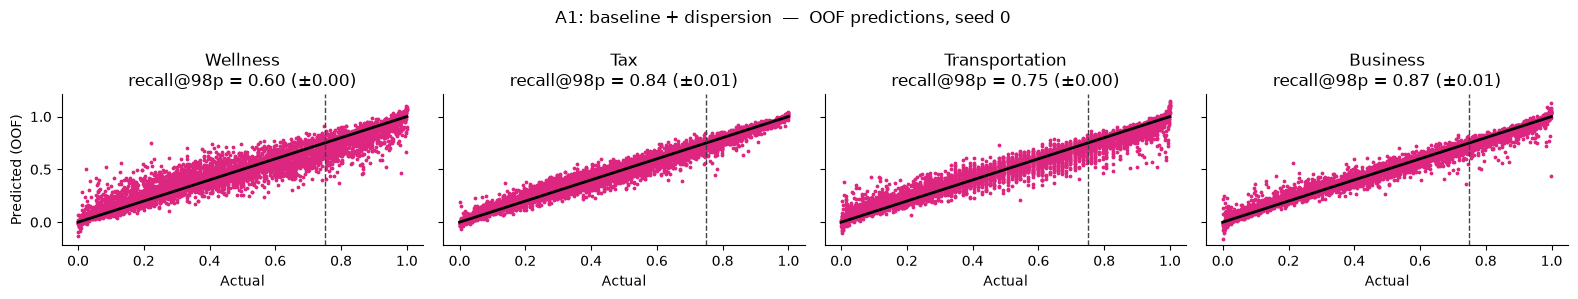

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
A1: baseline + dispersion,0.603683,0.844258,0.753146,0.867046,0.767033
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [8]:
# A1
def dispersion_features(grid_arr):
    """(n, 7, 7) -> (n, 70) float32. See the markdown above for the column groups."""
    n = len(grid_arr)
    flat = grid_arr.reshape(n, 49)
    masks = [(flat == d) for d in range(5)]
    rc = _COORDS.astype(np.float64)              # (49, 2) row/col of each cell
    D = _STEPS.astype(np.float64)                # (49, 49) Manhattan steps between cells
    cols = []

    for d in range(5):                           # shape of each district (4 cols each)
        m = masks[d]
        cnt = m.sum(1)
        safe = np.maximum(cnt, 1)
        cen = (m[:, :, None] * rc[None]).sum(1) / safe[:, None]
        var = (m[:, :, None] * (rc[None] - cen[:, None, :]) ** 2).sum(1) / safe[:, None]
        spread = np.sqrt(var.sum(1))
        rmin = np.where(m, rc[None, :, 0], np.inf).min(1)
        rmax = np.where(m, rc[None, :, 0], -np.inf).max(1)
        cmin = np.where(m, rc[None, :, 1], np.inf).min(1)
        cmax = np.where(m, rc[None, :, 1], -np.inf).max(1)
        bbox = np.where(cnt > 0, (rmax - rmin + 1) * (cmax - cmin + 1), 0.0)
        cen = np.where(cnt[:, None] > 0, cen, 3.0)   # absent district: centre, zero spread
        spread = np.where(cnt > 0, spread, 0.0)
        cols += [cen[:, 0], cen[:, 1], spread, bbox]

    for dx in range(5):                          # X -> Y distance structure (2 cols per pair)
        mx = masks[dx]
        cx_cnt = mx.sum(1)
        cx = np.maximum(cx_cnt, 1)
        for dy in range(5):
            my = masks[dy].astype(np.float64)
            cy = my.sum(1)
            # mean over X cells of (mean distance to ALL Y cells)
            mean_to_all = (my @ D.T) / np.maximum(cy, 1)[:, None]
            v = (mx * mean_to_all).sum(1) / cx
            cols.append(np.where((cy > 0) & (cx_cnt > 0), v, ABSENT_DISTANCE))
            # mean over X cells of (distance to the 2nd-NEAREST Y cell)
            dist_to_y = np.where(my[:, None, :] > 0, D[None, :, :], np.inf)
            second = np.partition(dist_to_y, 1, axis=2)[:, :, 1]
            v2 = (mx * np.where(np.isfinite(second), second, ABSENT_DISTANCE)).sum(1) / cx
            cols.append(np.where((cy > 1) & (cx_cnt > 0), v2, ABSENT_DISTANCE))

    return np.stack(cols, 1).astype(np.float32)


run_experiment_cv("A1: baseline + dispersion", with_group(dispersion_features), lgbm)
results_table_cv()

## A2 — Low-frequency spectral features (45 columns)

Blur the map and describe only the big smudges. The 2D DCT of each district's 7×7 mask decomposes
it into spatial waves; the low-frequency coefficients say things like "residential mass is heavier
on the left" or "industry splits into two lobes" — global layout no count or nearest-distance
feature sees, and that trees can't synthesize from per-cell inputs. We keep the 3×3 lowest
frequencies per district, as magnitudes. (The (0,0) coefficient is ∝ the district count —
a harmless duplicate.)

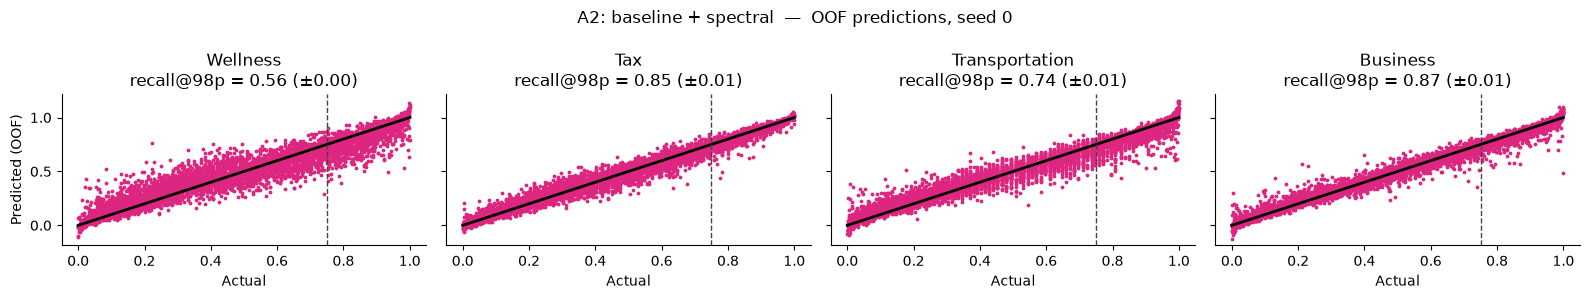

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
A2: baseline + spectral,0.559915,0.854062,0.744311,0.873815,0.758026
A1: baseline + dispersion,0.603683,0.844258,0.753146,0.867046,0.767033
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [9]:
# A2
from scipy.fft import dctn


def spectral_features(grid_arr, k=3):
    """(n, 7, 7) -> (n, 5*k*k) float32: |DCT-II| of each district mask, lowest k x k frequencies."""
    n = len(grid_arr)
    feats = []
    for d in range(5):
        mask = (grid_arr == d).astype(np.float64)
        coef = dctn(mask, axes=(1, 2), norm="ortho")
        feats.append(np.abs(coef[:, :k, :k]).reshape(n, k * k))
    return np.hstack(feats).astype(np.float32)


run_experiment_cv("A2: baseline + spectral", with_group(spectral_features), lgbm)
results_table_cv()

## A3 — Assignment-based commute cost (5 columns)

Joel's commute features send each home to its *nearest* job — but if ten homes share one nearby
job, nine of them actually travel farther. This computes the optimal *assignment* instead: the
cheapest way to match the whole residential distribution to a destination distribution (entropic
optimal transport / Sinkhorn, Manhattan cost). Five destinations: all jobs (industrial +
commercial + office), and each of the four non-residential districts separately (parks for
Wellness, shops for Tax/Business, ...). It's rush hour instead of the brochure.

Cost note: ~5,000 grids × 5 destinations of small Sinkhorn solves ≈ 1–3 min per advisor subset.

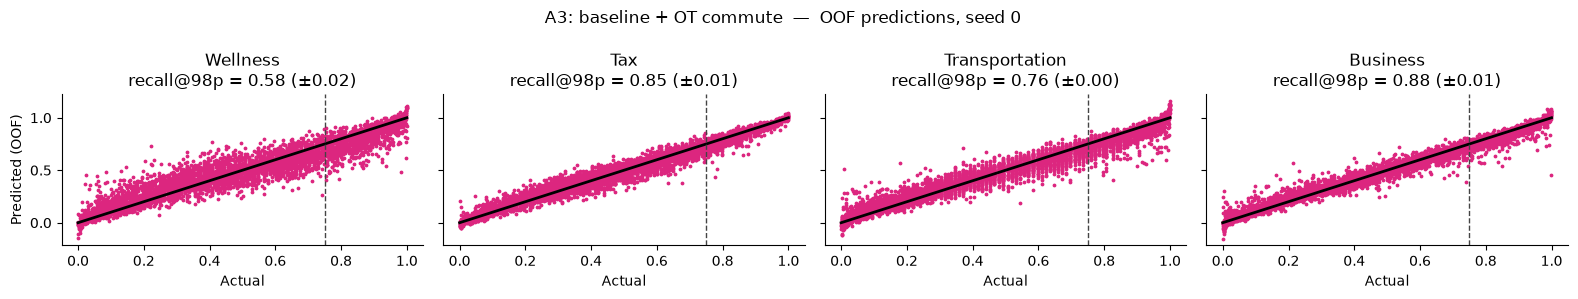

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
A2: baseline + spectral,0.559915,0.854062,0.744311,0.873815,0.758026
A3: baseline + OT commute,0.575927,0.847339,0.760643,0.878148,0.765514
A1: baseline + dispersion,0.603683,0.844258,0.753146,0.867046,0.767033
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [10]:
# A3
def _sinkhorn_cost(src_idx, dst_idx, D, reg=1.0, iters=60):
    """Entropic OT cost between uniform distributions on two cell sets (Manhattan cost D)."""
    C = D[np.ix_(src_idx, dst_idx)]
    K = np.exp(-C / reg)
    a = np.full(len(src_idx), 1.0 / len(src_idx))
    b = np.full(len(dst_idx), 1.0 / len(dst_idx))
    u = np.ones_like(a)
    for _ in range(iters):
        v = b / (K.T @ u)
        u = a / (K @ v)
    plan = u[:, None] * K * v[None, :]
    return float((plan * C).sum())


def ot_commute_features(grid_arr):
    """(n, 7, 7) -> (n, 5) float32: OT cost home->jobs, home->industrial/commercial/park/office."""
    n = len(grid_arr)
    flat = grid_arr.reshape(n, 49)
    D = _STEPS.astype(np.float64)
    out = np.full((n, 5), ABSENT_DISTANCE, dtype=np.float32)
    for i in range(n):
        src = np.flatnonzero(flat[i] == 0)
        if not src.size:
            continue
        dst_sets = [np.flatnonzero(np.isin(flat[i], [1, 2, 4]))] + \
                   [np.flatnonzero(flat[i] == d) for d in (1, 2, 3, 4)]
        for j, dst in enumerate(dst_sets):
            if dst.size:
                out[i, j] = _sinkhorn_cost(src, dst, D)
    return out


run_experiment_cv("A3: baseline + OT commute", with_group(ot_commute_features), lgbm)
results_table_cv()

## Phase A verdict → `CURRENT_FEATURES`

Adopt a group **per advisor** only where its recall@98p beats the baseline by more than the seed
spread (`results_table_cv("recall_spread")` shows the noise floor). Record adoptions below —
Phase B builds on `CURRENT_FEATURES`. If nothing wins, `CURRENT_FEATURES` stays the baseline,
which is a legitimate Phase A result (Joel's features are good).

In [11]:
# Update per Phase A results; keys must cover all four advisors.
# Example adoption:  CURRENT_FEATURES["Transportation"] = with_group(ot_commute_features)["Transportation"]
CURRENT_FEATURES = dict(BASELINE_FEATURES)

results_table_cv("recall_spread")

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.000000,0.000000,0.000000,0.000000,0.000000
A1: baseline + dispersion,0.005604,0.017647,0.008835,0.027620,0.014927
A2: baseline + spectral,0.008006,0.026891,0.022490,0.013810,0.017799
A3: baseline + OT commute,0.035228,0.020168,0.009639,0.015435,0.020117
BASELINE: LGBM / Joel features (Wellness +onehot),0.029624,0.021849,0.029719,0.017059,0.024563


# Phase B — Model experiments

Fixed features (`CURRENT_FEATURES` from Phase A); vary how the model is trained or combined.
Avoided on purpose (Joel showed they don't pay): hyperparameter sweeps, CNN end-models.

- **B1 quantile certification** — train a deliberate *low-ball* estimator (quantile loss): its
  prediction is "the score is probably at least this", a per-grid safety margin. Certifying on a
  pessimist can rank the boundary more safely than certifying on the average.
- **B2 boundary weighting** — weight training samples by closeness to 0.75: spend capacity where
  pass/fail is decided, not on distinguishing 0.1 from 0.3.
- **B3 heterogeneous stacking** — LightGBM + ridge + extra-trees blended by a learned referee.
  Different model families make different mistakes; Joel only averaged near-identical GBMs.
- **B4 pseudo-labeling** — the untapped resource: 495k unlabeled grids. The model labels them,
  keeps only its most confident calls as extra (down-weighted) training data, and retrains.
  Always evaluated on real labels only.

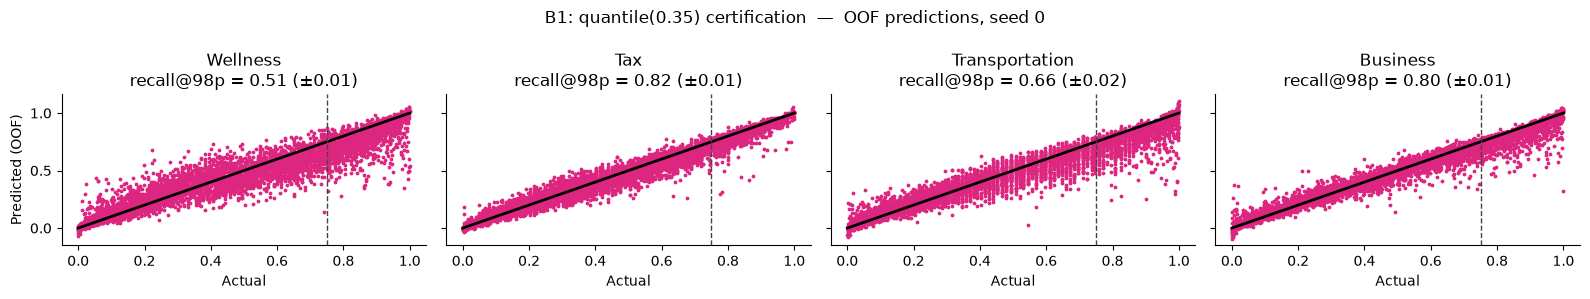

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
B1: quantile(0.35) certification,0.512677,0.822129,0.659705,0.797184,0.697924
A2: baseline + spectral,0.559915,0.854062,0.744311,0.873815,0.758026
A3: baseline + OT commute,0.575927,0.847339,0.760643,0.878148,0.765514
A1: baseline + dispersion,0.603683,0.844258,0.753146,0.867046,0.767033
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [12]:
# B1: quantile (pessimistic) LightGBM. alpha = which quantile the model predicts;
# 0.35 is a mild pessimist. If it helps, try 0.25 / 0.45 to bracket the sweet spot.
def lgbm_quantile(alpha=0.35):
    params = {**GBM_PARAMS, "objective": "quantile", "alpha": alpha}
    return lambda: lgb.LGBMRegressor(**params)


run_experiment_cv("B1: quantile(0.35) certification", CURRENT_FEATURES, lgbm_quantile(0.35))
results_table_cv()

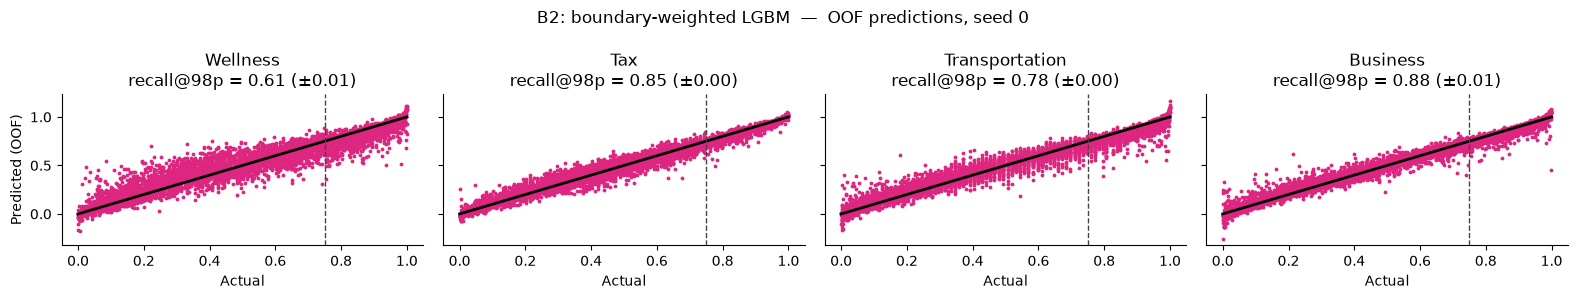

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
B1: quantile(0.35) certification,0.512677,0.822129,0.659705,0.797184,0.697924
A2: baseline + spectral,0.559915,0.854062,0.744311,0.873815,0.758026
A3: baseline + OT commute,0.575927,0.847339,0.760643,0.878148,0.765514
A1: baseline + dispersion,0.603683,0.844258,0.753146,0.867046,0.767033
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088
B2: boundary-weighted LGBM,0.605818,0.848739,0.784471,0.881126,0.780039


In [13]:
# B2: boundary-weighted training. Gaussian weight centred on 0.75 (sigma ~ the models'
# error scale); floor keeps the tails from being discarded entirely.
class BoundaryWeightedLGBM:
    def __init__(self, sigma=0.12, floor=0.25):
        self.sigma, self.floor = sigma, floor

    def fit(self, X, y):
        w = self.floor + (1 - self.floor) * np.exp(-0.5 * ((y - VALID_THRESHOLD) / self.sigma) ** 2)
        self.model = lgb.LGBMRegressor(**GBM_PARAMS)
        self.model.fit(X, y, sample_weight=w)
        return self

    def predict(self, X):
        return self.model.predict(X)


run_experiment_cv("B2: boundary-weighted LGBM", CURRENT_FEATURES, BoundaryWeightedLGBM)
results_table_cv()

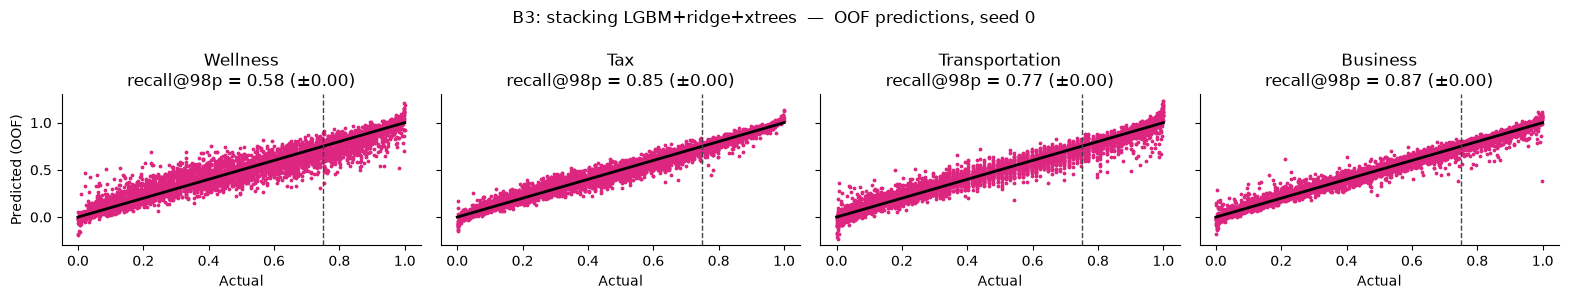

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
B1: quantile(0.35) certification,0.512677,0.822129,0.659705,0.797184,0.697924
A2: baseline + spectral,0.559915,0.854062,0.744311,0.873815,0.758026
A3: baseline + OT commute,0.575927,0.847339,0.760643,0.878148,0.765514
A1: baseline + dispersion,0.603683,0.844258,0.753146,0.867046,0.767033
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088
B3: stacking LGBM+ridge+xtrees,0.582066,0.851261,0.771084,0.874086,0.769624
B2: boundary-weighted LGBM,0.605818,0.848739,0.784471,0.881126,0.780039


In [14]:
# B3: heterogeneous stacking. StackingRegressor fits each level-0 model out-of-fold internally,
# then a ridge referee learns how much to trust each. ~15x the fits of a plain LGBM, so start
# with seeds=(0,) and rerun with all seeds only if it leads the table.
from sklearn.ensemble import ExtraTreesRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def stack():
    return StackingRegressor(
        estimators=[
            ("lgbm", lgb.LGBMRegressor(**GBM_PARAMS)),
            ("ridge", make_pipeline(StandardScaler(), RidgeCV())),
            ("xtrees", ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=0)),
        ],
        final_estimator=RidgeCV(), cv=4)


run_experiment_cv("B3: stacking LGBM+ridge+xtrees", CURRENT_FEATURES, stack, seeds=(0,))
results_table_cv()

In [15]:
# B4: pseudo-labeling (self-training) with the unlabeled 495k. Inside every fold: a teacher
# trained on the train folds labels a fixed 30k unlabeled sample; only its confident extremes
# (pred <= lo or >= hi) join the student's training data, down-weighted, capped at cap_ratio x
# the train-fold size. The OOF evaluation uses real labels only, so a teacher reinforcing its own
# mistakes shows up as a worse score, not a hidden one. No label leakage: the teacher never sees
# the test fold, and unlabeled grids have no labels to leak.
def run_pseudo_label_cv(name, feature_fn, model_fn, pool_size=30_000, lo=0.30, hi=0.90,
                        cap_ratio=2.0, pseudo_weight=0.3, seeds=(0,), n_splits=5):
    rng = np.random.default_rng(0)
    for advisor in range(4):
        aname = ADVISOR_NAMES[advisor]
        grids_subset, y = select_rated_subset(grids, ratings[:, advisor])
        ffn = _per_advisor(feature_fn, aname)
        mfn = _per_advisor(model_fn, aname)
        X = ffn(grids_subset)
        unl = rng.choice(np.flatnonzero(np.isnan(ratings[:, advisor])), pool_size, replace=False)
        Xu = ffn(grids[unl])

        recalls, yields, oof_first = [], [], None
        for seed in seeds:
            oof = np.empty(len(y))
            for train, test in KFold(n_splits, shuffle=True, random_state=seed).split(X):
                teacher = mfn()
                teacher.fit(X[train], y[train])
                pu = teacher.predict(Xu)
                sel = np.flatnonzero((pu <= lo) | (pu >= hi))
                cap = int(cap_ratio * len(train))
                if len(sel) > cap:  # keep the most extreme (most confident) pseudo-labels
                    sel = sel[np.argsort(-np.abs(pu[sel] - VALID_THRESHOLD))[:cap]]
                X_aug = np.vstack([X[train], Xu[sel]])
                y_aug = np.concatenate([y[train], pu[sel]])
                w_aug = np.concatenate([np.ones(len(train)), np.full(len(sel), pseudo_weight)])
                student = mfn()
                student.fit(X_aug, y_aug, sample_weight=w_aug)
                oof[test] = student.predict(X[test])
            r, yl = certify_at_precision(oof, y)
            recalls.append(r)
            yields.append(yl)
            if oof_first is None:
                oof_first = oof
        RESULTS_CV.append({
            "experiment": name, "advisor": aname,
            "recall_at_98p": float(np.mean(recalls)),
            "recall_spread": float(max(recalls) - min(recalls)),
            "yield_at_98p": float(np.mean(yields)),
            "pr_auc": average_precision_score(y >= VALID_THRESHOLD, oof_first),
            "r2_oof": r2_score(y, oof_first),
        })
        print(f"{name} / {aname}: recall@98p = {np.mean(recalls):.3f}")


run_pseudo_label_cv("B4: pseudo-labels (30k pool)", CURRENT_FEATURES, lgbm)
results_table_cv()

B4: pseudo-labels (30k pool) / Wellness: recall@98p = 0.578
B4: pseudo-labels (30k pool) / Tax: recall@98p = 0.843
B4: pseudo-labels (30k pool) / Transportation: recall@98p = 0.744
B4: pseudo-labels (30k pool) / Business: recall@98p = 0.872


advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
B1: quantile(0.35) certification,0.512677,0.822129,0.659705,0.797184,0.697924
A2: baseline + spectral,0.559915,0.854062,0.744311,0.873815,0.758026
B4: pseudo-labels (30k pool),0.578062,0.842857,0.743775,0.872461,0.759289
A3: baseline + OT commute,0.575927,0.847339,0.760643,0.878148,0.765514
A1: baseline + dispersion,0.603683,0.844258,0.753146,0.867046,0.767033
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088
B3: stacking LGBM+ridge+xtrees,0.582066,0.851261,0.771084,0.874086,0.769624
B2: boundary-weighted LGBM,0.605818,0.848739,0.784471,0.881126,0.780039


## Phase B verdict

Same adoption rule: a model change wins per advisor only if it beats the Phase A incumbent by more
than the seed spread (rerun the leader with `seeds=(0, 1, 2)` if it was screened with one seed).
Log adopted winners + numbers in `fatak_notes.md`, then move to Phase C.

## Best-per-advisor lineup

The four advisors are modeled independently (separate labels, features, models), so the best
recipe can be picked **per advisor** and composed into one lineup with no retraining: the
lineup's per-advisor metrics are exactly the winning experiments' logged rows, re-logged under
one name so the table's mean column shows what mixing recipes buys over any single one.

Two caveats: B3/B4 rows were screened with `seeds=(0,)`, so they compete on noisier estimates
than the 3-seed rows; and taking the per-advisor max is mildly winner's-curse-prone (selection
inflates the composite mean a little). Confirm any adopted lineup with a fresh-seed rerun before
building the final models on it.


In [ ]:
# Compose the best logged recipe per advisor into one lineup row per advisor.
LINEUP_NAME = "LINEUP: best per advisor"

_df = pd.DataFrame(RESULTS_CV).drop_duplicates(subset=["experiment", "advisor"], keep="last")
_candidates = _df[~_df["experiment"].str.startswith(("LINEUP", "sanity"))]

RESULTS_CV[:] = [r for r in RESULTS_CV if r["experiment"] != LINEUP_NAME]  # rerun-safe
for aname in ADVISOR_NAMES:
    best = _candidates[_candidates["advisor"] == aname].nlargest(1, "recall_at_98p").iloc[0]
    print(f"{aname:<16} <- {best['experiment']}  "
          f"(recall@98p = {best['recall_at_98p']:.3f}, spread = {best['recall_spread']:.3f})")
    RESULTS_CV.append({**best.to_dict(), "experiment": LINEUP_NAME})

results_table_cv()


# Phase C — Latent-space assessment

*(next: C1 PCA/NMF latents from all 500k grids · C2 small conv autoencoder — then the written
verdict on whether representation learning is the right tool here)*